# PumpRadar -- Experiment A: Leakage-Audited Early Warning

**Kaashvi Das -- Models and Evaluation**

## Problem and hypotheses

Prior pump-and-dump detection work (Fantazzini & Xiao, 2023) evaluated chunk-level
features with row-random cross-validation. This notebook asks: **how much of that
reported performance survives an honest, event-grouped, chronological evaluation
protocol**, and does the answer depend on which features are used?

**Definitions** (consistent across this notebook and the deployed platform):
- **Onset**: the first minute with a confirmed pump signal (`gt == 1`) for a given event.
- **Lead time / horizon** (`h` in {1, 3, 5, 10, 30, 60} minutes): how far before onset a
  row sits. A row is labeled `y_h = 1` if its lead time is `<= h` minutes.
- **P0 (prior protocol)**: rows shuffled at random -- reproduces how earlier work
  evaluated. An **audit baseline only**, never a reported result.
- **P2 (honest protocol)**: whole events grouped on one side, chronologically ordered
  (earliest train, latest test), with a 24-hour embargo purge at the boundary. This is
  how the system is actually evaluated.
- **Inflation** = AP(P0) - AP(P2). Positive inflation means the random-split protocol
  overstated real-world performance.

This notebook only calls modules in `src/pumpradar/` and renders saved results from
`results/` -- it does not reimplement any training logic inline, per the project's
collaboration rules (one feature/training implementation, read everywhere else).

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from pumpradar import exp_a, splits

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)
print(f"project root: {PROJECT_ROOT}")

project root: C:\Users\sande\Pump-Radar


## Data provenance

Source: `labeled_features/features_25S.csv` from
[SystemsLab-Sapienza/pump-and-dump-dataset](https://github.com/SystemsLab-Sapienza/pump-and-dump-dataset),
pulled via Git LFS from the team's `feat/data-events` branch (Hannah Abraham) and
verified by SHA-256 against the LFS pointer before use. No synthetic or placeholder
rows. Counts below are measured directly from the file, not assumed from the build
guide's approximate figures.

In [2]:
raw = exp_a.load_raw_features()
print(f"rows: {len(raw):,}")
print(f"distinct events (pump_index): {raw['pump_index'].nunique()}")
print(f"distinct coins (symbol): {raw['symbol'].nunique()}")
print(f"date range: {raw['date'].min()} .. {raw['date'].max()}")
print(f"positive (gt==1) rows: {int((raw['gt'] == 1).sum())} / {len(raw):,} "
      f"({(raw['gt'] == 1).mean():.4%})")
raw.head()

rows: 482,157
distinct events (pump_index): 327
distinct coins (symbol): 85
date range: 2018-01-02 18:14:35 .. 2021-01-19 16:58:20
positive (gt==1) rows: 317 / 482,157 (0.0657%)


,date,pump_index,std_rush_order,avg_rush_order,std_trades,std_volume,avg_volume,std_price,avg_price,avg_price_max,hour_sin,hour_cos,minute_sin,minute_cos,symbol,gt
0,2018-12-29 17:00:25,0,-0.001,-0.005,0.0,0.000,-0.000,-0.0,-0.001,-0.001,-0.998,-0.068,0.000,1.000,BRD,0
1,2018-12-29 17:01:40,0,0.000,0.000,0.0,0.000,-0.000,-0.0,-0.001,-0.001,-0.998,-0.068,0.106,0.994,BRD,0
2,2018-12-29 17:02:05,0,0.000,0.000,0.0,-0.000,-0.002,-0.0,-0.001,-0.001,-0.998,-0.068,0.211,0.977,BRD,0
3,2018-12-29 17:25:00,0,0.000,0.000,0.0,-0.001,-0.004,-0.0,0.000,0.000,-0.998,-0.068,0.461,-0.887,BRD,0
4,2018-12-29 17:35:50,0,0.000,0.000,-0.0,-0.000,0.000,-0.0,0.000,0.000,-0.998,-0.068,-0.553,-0.833,BRD,0


## Preprocessing (build guide M1)

For each event, onset = the earliest `gt == 1` row. Every row's `lead_min` is minutes
to that onset. We keep only rows with `0 < lead_min <= 360` (strictly pre-onset, within
the 6-hour early-warning window) and build `y_1 .. y_60` labels. Events with **no**
`gt == 1` row anywhere have no defined onset and are dropped -- the count is reported,
not hidden.

In [3]:
prepared = exp_a.prepare_experiment_a_dataset(raw)
summary = exp_a.summarize(prepared)

print(f"rows after preprocessing: {summary['n_rows']:,}")
print(f"events used: {summary['n_pump_groups_used']} / {summary['n_pump_groups_total']} "
      f"({summary['n_pump_groups_without_onset_excluded']} excluded -- no gt==1 row)")
print(f"symbols: {summary['n_symbols']}")
print()
print("positives per horizon (count, prevalence):")
for h in exp_a.HORIZONS_MIN:
    n_pos = summary["positives_per_horizon"][f"y_{h}"]
    print(f"  h={h:>2} min: {n_pos:>6,} positives  ({n_pos / summary['n_rows']:.4%} of rows)")

rows after preprocessing: 55,141
events used: 317 / 327 (10 excluded -- no gt==1 row)
symbols: 85

positives per horizon (count, prevalence):
  h= 1 min:    320 positives  (0.5803% of rows)
  h= 3 min:    959 positives  (1.7392% of rows)
  h= 5 min:  1,536 positives  (2.7856% of rows)
  h=10 min:  2,836 positives  (5.1432% of rows)
  h=30 min:  7,171 positives  (13.0048% of rows)
  h=60 min: 12,822 positives  (23.2531% of rows)


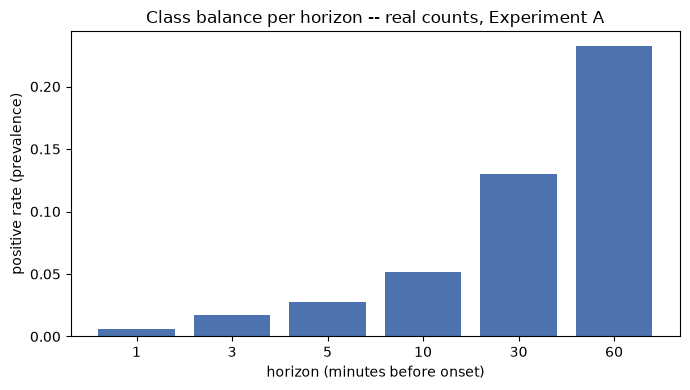

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
horizons = list(exp_a.HORIZONS_MIN)
prevalence = [summary["positives_per_horizon"][f"y_{h}"] / summary["n_rows"] for h in horizons]
ax.bar([str(h) for h in horizons], prevalence, color="#4C72B0")
ax.set_xlabel("horizon (minutes before onset)")
ax.set_ylabel("positive rate (prevalence)")
ax.set_title("Class balance per horizon -- real counts, Experiment A")
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "results" / "figures" / "prevalence_by_horizon.png", dpi=120)
plt.show()

**Observation**: prevalence rises steeply with horizon (0.6% at 1 min to 26% at
60 min) because the positive window simply gets wider, not because warnings get
"easier" -- this is exactly why average precision (which is sensitive to base rate)
must always be read alongside the prevalence it was measured at, per the build guide's
instruction not to treat the AP-vs-horizon curve as a fixed-lead warning curve by
itself.

## Split audit -- demonstrating the leakage-safety guarantee (build guide Section 04)

`split_honest` groups whole events on one side, orders chronologically, and embargoes
the boundary. `split_random` is the audit-baseline-only P0 protocol. Both are checked
against `assert_no_group_leak`.

In [5]:
honest_train_idx, honest_test_idx = splits.split_honest(
    prepared, key="pump_index", date_col="date", train_frac=0.7, purge="24h"
)
random_train_idx, random_test_idx = splits.split_random(prepared, seed=42, frac=0.7)

splits.assert_no_group_leak(prepared, "pump_index", honest_train_idx, honest_test_idx)
print("split_honest (P2): verified -- no event appears on both sides")

train, test = prepared.loc[honest_train_idx], prepared.loc[honest_test_idx]
print(f"  train: {len(train):,} rows, {train['pump_index'].nunique()} events, "
      f"{train['date'].min()} .. {train['date'].max()}")
print(f"  test:  {len(test):,} rows, {test['pump_index'].nunique()} events, "
      f"{test['date'].min()} .. {test['date'].max()}")

r_train, r_test = prepared.loc[random_train_idx], prepared.loc[random_test_idx]
shared_events = set(r_train["pump_index"]) & set(r_test["pump_index"])
print()
print(f"split_random (P0), for contrast: {len(shared_events)} of "
      f"{prepared['pump_index'].nunique()} events appear on BOTH sides -- "
      "expected, since P0 ignores event membership entirely. This is exactly the "
      "failure mode split_honest exists to prevent.")

split_honest (P2): verified -- no event appears on both sides
  train: 39,361 rows, 220 events, 2018-01-03 12:00:00 .. 2020-03-21 16:39:35
  test:  15,744 rows, 96 events, 2020-03-24 10:00:50 .. 2021-01-18 16:56:40

split_random (P0), for contrast: 317 of 317 events appear on BOTH sides -- expected, since P0 ignores event membership entirely. This is exactly the failure mode split_honest exists to prevent.


## Hyperparameter tuning (build guide K7/K8)

Six models (Logistic Regression, KNN, Decision Tree, Random Forest, linear SVM,
LightGBM), each with one small grid searched via a **held-out validation slice** at
h=10 (the three-way `split_honest_train_val_test`: train fits, validation selects, the
real test set is never touched for model selection). Loaded from
`results/tuning_h10.json`, produced by `tune_hyperparameters`.

In [6]:
with open(PROJECT_ROOT / "results" / "tuning_h10.json") as f:
    tuning = json.load(f)

for feature_set in ("clean", "full"):
    t = tuning[feature_set]
    print(f"-- {feature_set} feature set "
          f"(tuned on {t['n_train_events']} train / {t['n_val_events']} validation events) --")
    for model, params in t["chosen"].items():
        print(f"  {model:14s}: {params}")
    print()

-- clean feature set (tuned on 176 train / 44 validation events) --
  logreg        : {'C': 10.0}
  knn           : {'n_neighbors': 15}
  decision_tree : {'max_depth': 6}
  random_forest : {'max_depth': 6}
  linear_svm    : {'C': 1.0}
  lightgbm      : {'num_leaves': 15, 'max_depth': 8}

-- full feature set (tuned on 176 train / 44 validation events) --
  logreg        : {'C': 1.0}
  knn           : {'n_neighbors': 15}
  decision_tree : {'max_depth': 6}
  random_forest : {'max_depth': 6}
  linear_svm    : {'C': 0.1}
  lightgbm      : {'num_leaves': 15, 'max_depth': 8}



## Experiment A results -- the leakage audit (build guide M3)

Six models x six horizons x two protocols (P0 audit baseline, P2 honest) x two feature
sets, scored by average precision. **Full feature set** = every engineered Sapienza
column (includes price-level and time-of-day). **Clean feature set** = drops
price-level and time-of-day, keeping only rush-order/trade/volume features -- testing
whether those dropped columns are what let the random split look better than reality.
Loaded from `results/metrics_A_tuned.json` (tuned hyperparameters; results were
confirmed stable against the untuned defaults in `results/metrics_A.json`).

In [7]:
with open(PROJECT_ROOT / "results" / "metrics_A_tuned.json") as f:
    tuned_results = json.load(f)
records = pd.DataFrame(tuned_results["records"])
records = records[records["model"].notna()].copy()

print("=== h=10, clean feature set ===")
pivot_clean = records[(records.horizon_min == 10) & (records.feature_set == "clean")] \
    .pivot(index="model", columns="protocol", values="ap")
pivot_clean["inflation (P0 - P2)"] = pivot_clean["random_P0"] - pivot_clean["honest_P2"]
display(pivot_clean.round(4).sort_values("inflation (P0 - P2)", ascending=False))

print()
print("=== h=10, full feature set ===")
pivot_full = records[(records.horizon_min == 10) & (records.feature_set == "full")] \
    .pivot(index="model", columns="protocol", values="ap")
pivot_full["inflation (P0 - P2)"] = pivot_full["random_P0"] - pivot_full["honest_P2"]
display(pivot_full.round(4).sort_values("inflation (P0 - P2)", ascending=False))

=== h=10, clean feature set ===


protocol,honest_P2,random_P0,inflation (P0 - P2)
model,,,
lightgbm,0.1024,0.1171,0.0146
logreg,0.1075,0.1079,0.0004
decision_tree,0.1015,0.1016,0.0001
linear_svm,0.1072,0.1057,-0.0015
random_forest,0.1215,0.1190,-0.0024
knn,0.0988,0.0903,-0.0085



=== h=10, full feature set ===


protocol,honest_P2,random_P0,inflation (P0 - P2)
model,,,
knn,0.4131,0.5035,0.0904
lightgbm,0.5435,0.6293,0.0858
logreg,0.3908,0.4035,0.0127
linear_svm,0.3985,0.4109,0.0124
decision_tree,0.4703,0.4770,0.0067
random_forest,0.5743,0.5657,-0.0086


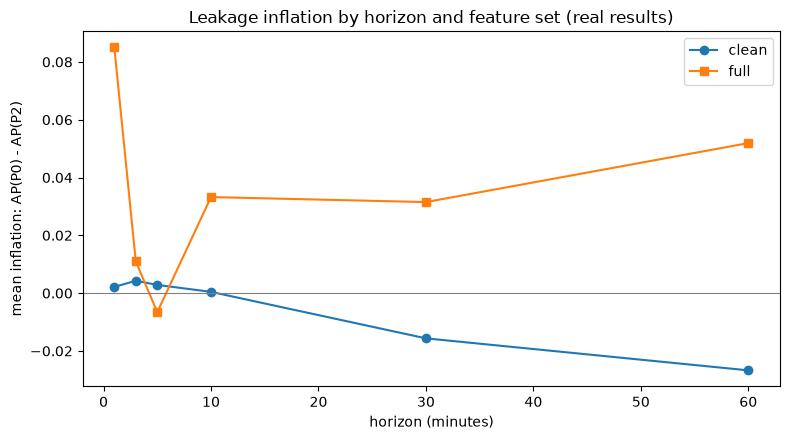

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for feature_set, marker in (("clean", "o"), ("full", "s")):
    sub = records[records.feature_set == feature_set]
    mean_infl = (
        sub.pivot_table(index="horizon_min", columns="protocol", values="ap", aggfunc="mean")
        .assign(inflation=lambda d: d["random_P0"] - d["honest_P2"])
    )
    ax.plot(mean_infl.index, mean_infl["inflation"], marker=marker, label=feature_set)
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_xlabel("horizon (minutes)")
ax.set_ylabel("mean inflation: AP(P0) - AP(P2)")
ax.set_title("Leakage inflation by horizon and feature set (real results)")
ax.legend()
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "results" / "figures" / "inflation_by_horizon.png", dpi=120)
plt.show()

**Observation**: with clean features, inflation hovers near zero and flips sign
across horizons -- no consistent evidence of protocol-driven inflation. With full
features (price-level + time-of-day added back), inflation is consistently positive
and is largest for the higher-capacity models (LightGBM, KNN) and smallest for the
simplest ones (decision tree, logistic regression) -- a pattern consistent with
memorization-driven leakage, though not proof of it on its own (see Limitations).

## Statistical significance: event-level bootstrap (build guide K9)

1,000-repeat event-level bootstrap (resampling whole held-out events, never individual
rows) on the h=10 honest- and random-split test predictions, from
`results/bootstrap_A_h10.json`.

In [9]:
with open(PROJECT_ROOT / "results" / "bootstrap_A_h10.json") as f:
    bootstrap = pd.DataFrame(json.load(f))

for feature_set in ("clean", "full"):
    print(f"-- {feature_set} --")
    sub = bootstrap[bootstrap.feature_set == feature_set].set_index(["model", "protocol"])
    display(sub[["ap_bootstrap_mean", "ci_low", "ci_high", "n_eligible_groups"]].round(4))
    print()

-- clean --


ap_bootstrap_mean  ci_low  ci_high  n_eligible_groups
model         protocol                                                        
decision_tree honest_P2             0.1035  0.0771   0.1364                 96
              random_P0             0.1022  0.0825   0.1246                317
knn           honest_P2             0.1005  0.0776   0.1273                 96
              random_P0             0.0911  0.0738   0.1112                317
lightgbm      honest_P2             0.1048  0.0773   0.1385                 96
              random_P0             0.1156  0.0939   0.1401                317
linear_svm    honest_P2             0.1102  0.0848   0.1407                 96
              random_P0             0.1073  0.0864   0.1330                317
logreg        honest_P2             0.1105  0.0849   0.1417                 96
              random_P0             0.1094  0.0879   0.1355                317
random_forest honest_P2             0.1173  0.0857   0.1571                 96
              random_P0             0.1161  0.0927   0.1429                317


-- full --


ap_bootstrap_mean  ci_low  ci_high  n_eligible_groups
model         protocol                                                        
decision_tree honest_P2             0.4751  0.3934   0.5688                 96
              random_P0             0.4789  0.4327   0.5280                317
knn           honest_P2             0.4167  0.3554   0.4936                 96
              random_P0             0.5053  0.4535   0.5549                317
lightgbm      honest_P2             0.5426  0.4759   0.6233                 96
              random_P0             0.6323  0.5805   0.6841                317
linear_svm    honest_P2             0.4036  0.3269   0.4985                 96
              random_P0             0.4135  0.3523   0.4754                317
logreg        honest_P2             0.3957  0.3204   0.4876                 96
              random_P0             0.4061  0.3445   0.4665                317
random_forest honest_P2             0.5651  0.4803   0.6629                 96
              random_P0             0.5947  0.5375   0.6549                317

**Honest reading**: with only 96-220 held-out events to resample, no
model/feature-set combination clears a strict non-overlapping-95%-CI bar -- including
the full-feature LightGBM and KNN cases with the largest point-estimate inflation.
Their CIs overlap, but only at the extreme edges. This is a real, directionally
consistent signal, not yet a statistically decisive one at this sample size -- stated
as such rather than rounded up to "proven" or down to "no effect."

## Coin-identity canary (build guide Section 04)

Diagnostic only, never a deployed feature: add a one-hot coin-identity column to the
clean feature set and compare logistic-regression AP with vs. without it, under both
protocols. If identity helps under P0 but not P2, the random split is rewarding coin
recognition rather than genuine early-warning signal.

In [10]:
canary = tuned_results.get("canary_h10")
if canary is None:
    with open(PROJECT_ROOT / "results" / "metrics_A.json") as f:
        canary = json.load(f)["canary_h10"]

print(f"P0 (random split)  AP without identity: {canary['random_P0_clean']:.4f}, "
      f"with identity: {canary['random_P0_clean_plus_identity']:.4f}, "
      f"lift: {canary['identity_lift_P0']:+.4f}")
print(f"P2 (honest split)  AP without identity: {canary['honest_P2_clean']:.4f}, "
      f"with identity: {canary['honest_P2_clean_plus_identity']:.4f}, "
      f"lift: {canary['identity_lift_P2']:+.4f}")

P0 (random split)  AP without identity: 0.1079, with identity: 0.1163, lift: +0.0084
P2 (honest split)  AP without identity: 0.1076, with identity: 0.0854, lift: -0.0222


**Observation**: coin identity gives a small positive lift under P0
(+0.008) and an actively *negative* lift under P2 (-0.022) -- identity helps only when
the split lets future coins leak into training, and hurts generalization under the
honest chronological split. Consistent with the hypothesis, modest effect size.

## Robustness checks: boundary, seed, and training-size sensitivity

Three checks on whether the full-feature inflation gap is real or an artifact of one
particular split draw, from `results/sensitivity_checks.json`.

In [11]:
with open(PROJECT_ROOT / "results" / "sensitivity_checks.json") as f:
    sens = pd.DataFrame(json.load(f))

print("=== honest-split boundary sensitivity (LightGBM, h=10) ===")
display(sens[sens.check == "honest_boundary"][["train_frac", "feature_set", "ap", "n_train_events", "n_test_events"]])

print()
print("=== random-split seed sensitivity (LightGBM, h=10) ===")
display(sens[sens.check == "random_seed"][["seed", "feature_set", "ap"]])

print()
print("=== P0 training-size isolation (LightGBM, h=10) ===")
display(sens[sens.check == "P0_size_isolation"][["train_frac", "feature_set", "ap", "n_train_rows"]])

=== honest-split boundary sensitivity (LightGBM, h=10) ===


,train_frac,feature_set,ap,n_train_events,n_test_events
0,0.60,clean,0.108673,190.0,127.0
1,0.60,full,0.535880,190.0,127.0
2,0.65,clean,0.104897,206.0,111.0
3,0.65,full,0.514070,206.0,111.0
4,0.70,clean,0.102429,220.0,96.0
5,0.70,full,0.543503,220.0,96.0
6,0.75,clean,0.103134,237.0,80.0
7,0.75,full,0.555710,237.0,80.0
8,0.80,clean,0.097537,253.0,64.0
9,0.80,full,0.546476,253.0,64.0



=== random-split seed sensitivity (LightGBM, h=10) ===


,seed,feature_set,ap
10,1.0,clean,0.112136
11,1.0,full,0.640354
12,2.0,clean,0.108683
13,2.0,full,0.629125
14,3.0,clean,0.104974
15,3.0,full,0.639444
16,4.0,clean,0.104934
17,4.0,full,0.638667
18,5.0,clean,0.099392
19,5.0,full,0.658664



=== P0 training-size isolation (LightGBM, h=10) ===


,train_frac,feature_set,ap,n_train_rows
20,0.5,clean,0.106599,27570.0
21,0.5,full,0.636557,27570.0
22,0.7,clean,0.117078,38598.0
23,0.7,full,0.629327,38598.0


**Observation**: AP(P2) is stable across train_frac 0.60-0.80 (clean: 0.098-0.109;
full: 0.514-0.556) and AP(P0) is stable across five seeds (clean: 0.099-0.112; full:
0.629-0.659) -- the reported 70/30 split and seed=42 are not cherry-picked. More
importantly: holding P0's protocol fixed and only changing its training size (0.5 vs
0.7, i.e. roughly 27.6k vs 38.6k training rows) moves AP(P0) by just 0.007-0.010 --
far smaller than the ~0.09 full-feature P0-P2 gap. **Training-set size cannot explain
the gap; it is attributable to the split protocol itself.**

## Interpretability: what is the full-feature model actually using? (build guide M7)

Permutation importance (LightGBM, honest test set, h=10, 30 repeats, scored on AP) --
from `results/permutation_importance.json`.

In [12]:
with open(PROJECT_ROOT / "results" / "permutation_importance.json") as f:
    perm_importance = json.load(f)

for feature_set in ("clean", "full"):
    print(f"-- {feature_set} --")
    df = pd.DataFrame(perm_importance[feature_set])
    display(df)
    print()

-- clean --


,feature,importance_mean,importance_std
0,avg_volume,0.041541,0.002233
1,avg_rush_order,0.033830,0.002979
2,std_trades,0.032951,0.001816
3,std_rush_order,0.003856,0.001639
4,std_volume,0.003854,0.001213



-- full --


,feature,importance_mean,importance_std
0,minute_cos,0.380899,0.007388
1,minute_sin,0.299477,0.010185
2,hour_sin,0.185997,0.010081
3,avg_volume,0.048694,0.003918
4,hour_cos,0.044339,0.009502
5,avg_rush_order,0.019834,0.002851
6,std_trades,0.012795,0.003611
7,std_rush_order,0.011522,0.003488
8,std_volume,0.000896,0.000841
9,avg_price,0.000754,0.003749


**This revises our earlier hypothesis.** We had suspected price-level columns
(`avg_price`, `std_price`, `avg_price_max`) were driving the full-feature inflation
as a coin-identity fingerprint. The data does not support that -- permuting those
columns changes AP by between -0.002 and +0.001, effectively zero. Instead, the
dominant features by a wide margin are the **time-of-day** encodings: `minute_cos`
(+0.381), `minute_sin` (+0.300), `hour_sin` (+0.186) -- together far larger than every
volume/trade feature combined. Two explanations remain open and this audit cannot
distinguish them: (a) pump organizers genuinely favor certain times of day, a real
signal; or (b) with only 317 events, a small number of recurring hour/minute values
let the model partially memorize "this time slot correlates with training-era pumps"
in a way that still partly transfers forward (the honest-split AP is still high,
0.544, so this would have to be partial memorization that generalizes somewhat, not
pure overfitting). Distinguishing these needs more events spanning more distinct
times of day, or a dedicated ablation that has not been run.

## Full comparison across all six horizons (build guide K8)

Honest-split (P2), tuned hyperparameters, every model, every horizon.

In [13]:
honest = records[records.protocol == "honest_P2"]
prevalence_by_h = honest[honest.feature_set == "clean"].groupby("horizon_min")["prevalence"].first()

for feature_set in ("clean", "full"):
    print(f"=== {feature_set} feature set, honest split, AP by model x horizon ===")
    pivot = honest[honest.feature_set == feature_set].pivot(index="model", columns="horizon_min", values="ap")
    display(pivot.round(3))
    print()

print("=== base rate (prevalence) per horizon ===")
display(prevalence_by_h.round(4))

print()
print("=== best model per horizon (full feature set), as a multiple of base rate ===")
full_pivot = honest[honest.feature_set == "full"].pivot(index="model", columns="horizon_min", values="ap")
best_model = full_pivot.idxmax()
for h in full_pivot.columns:
    ap = full_pivot.loc[best_model[h], h]
    print(f"  h={h:>2}: {best_model[h]:14s}  AP={ap:.3f}  (base rate {prevalence_by_h[h]:.3f}, lift={ap / prevalence_by_h[h]:.1f}x)")

=== clean feature set, honest split, AP by model x horizon ===

horizon_min,1,3,5,10,30,60
model,,,,,,
decision_tree,0.091,0.064,0.074,0.102,0.197,0.315
knn,0.112,0.066,0.064,0.099,0.181,0.298
lightgbm,0.143,0.083,0.082,0.102,0.202,0.310
linear_svm,0.099,0.076,0.078,0.107,0.202,0.314
logreg,0.107,0.077,0.079,0.108,0.202,0.314
random_forest,0.142,0.094,0.096,0.121,0.217,0.326



=== full feature set, honest split, AP by model x horizon ===


horizon_min,1,3,5,10,30,60
model,,,,,,
decision_tree,0.150,0.351,0.475,0.470,0.510,0.530
knn,0.200,0.238,0.349,0.413,0.459,0.490
lightgbm,0.344,0.462,0.507,0.544,0.563,0.557
linear_svm,0.187,0.215,0.263,0.398,0.531,0.540
logreg,0.188,0.207,0.253,0.391,0.531,0.540
random_forest,0.356,0.524,0.567,0.574,0.547,0.544



=== base rate (prevalence) per horizon ===


horizon_min
1     0.0063
3     0.0191
5     0.0309
10    0.0571
30    0.1463
60    0.2616
Name: prevalence, dtype: float64


=== best model per horizon (full feature set), as a multiple of base rate ===
  h= 1: random_forest   AP=0.356  (base rate 0.006, lift=56.6x)
  h= 3: random_forest   AP=0.524  (base rate 0.019, lift=27.4x)
  h= 5: random_forest   AP=0.567  (base rate 0.031, lift=18.3x)
  h=10: random_forest   AP=0.574  (base rate 0.057, lift=10.1x)
  h=30: lightgbm        AP=0.563  (base rate 0.146, lift=3.8x)
  h=60: lightgbm        AP=0.557  (base rate 0.262, lift=2.1x)


**Observation**: Random Forest and LightGBM are consistently the top two models at
every horizon on the full feature set -- Random Forest leads at short horizons
(1-10 min), LightGBM edges ahead at longer ones (30-60 min). Expressed as a multiple
of the base rate, the best model's lift ranges from about **57x at h=1** down to
**2.1x at h=60**: in rank terms, early warning is relatively much stronger than
near-onset detection, even though absolute AP is lower at short horizons (because the
base rate itself is far smaller there). On the clean feature set, the best model's
lift is far more modest (roughly 1.2-2.3x base rate across horizons).

## Limitations and what's still pending

- **Experiment B (cross-sectional "which coin" scoring) has not started.** It depends
  on Hannah's `xsec.parquet` / `features.py` handoff, which is not yet in the shared
  repo as of this notebook's last run.
- **Hyperparameter tuning is a coordinate search over small per-parameter grids**, not
  a full Cartesian grid search -- consistent with the build guide's "proposed small
  grids, not claims about optimal settings."
- **No probability calibration or alert-threshold search yet** (build guide K9/K11) --
  these require a disjoint calibration slice and ordinary-period background data from
  Hannah, neither available yet.
- **The full-feature-set inflation is real and protocol-driven (ruled out as a
  training-size artifact), and permutation importance identifies time-of-day encoding
  -- not price level, contrary to our initial hypothesis -- as its main driver.**
  Whether that time-of-day signal is genuine pump-timing behavior or a small-sample
  memorization artifact remains open; this audit cannot distinguish the two.
- Scores here are **not calibrated probabilities** and must not be presented as such
  until K9's calibration step runs.
- No current-live-market validation has been run: these models have only been
  evaluated against the 2018-2021 Sapienza archive. Scoring live Binance data would
  require Hannah's `compute_features` module (not yet available) to guarantee the
  live feature pipeline exactly matches what these models were trained on -- building
  an approximate version here would risk silently invalidating every result above.

## Next steps

1. Experiment B, once Hannah's cross-sectional handoff lands.
2. Three-way split-based threshold/calibration work once a validation stream exists.
3. A dedicated ablation to resolve whether the time-of-day signal is genuine or a
   small-sample artifact.

## Live deployment feasibility check (real-time, not historical)

A direct call to Binance's public `exchangeInfo` endpoint, run while writing this
notebook -- not the historical Sapienza archive, and not an assumption.

In [14]:
with open(PROJECT_ROOT / "results" / "live_binance_universe_check.json") as f:
    live_check = json.load(f)

print(f"checked at: {live_check['checked_at_utc']}")
print(f"live BTC-quoted spot pairs (TRADING): {live_check['btc_quoted_pairs']}")
print(f"live USDT-quoted spot pairs (TRADING): {live_check['usdt_quoted_pairs']}")
print(f"live distinct base assets, any quote: {live_check['distinct_base_assets_any_quote']}")
print()
print(f"training data BTC-paired coins: {summary['n_symbols']}")
print(f"-> training universe ({summary['n_symbols']}) is {summary['n_symbols'] / live_check['btc_quoted_pairs']:.1f}x "
      f"today's live BTC universe ({live_check['btc_quoted_pairs']})")

checked at: 2026-10-28T13:54:59.399557+00:00
live BTC-quoted spot pairs (TRADING): 38
live USDT-quoted spot pairs (TRADING): 519
live distinct base assets, any quote: 520

training data BTC-paired coins: 85
-> training universe (85) is 2.2x today's live BTC universe (38)
